In [1]:
#Imports
import pandas as pd
import numpy as np
import nltk
import re
nltk.download("stopwords")
from nltk.corpus import stopwords
from gensim.corpora import Dictionary
from gensim.models.ldamodel import LdaModel
from sklearn.metrics.pairwise import cosine_similarity
from recpack.util import get_top_K_ranks
import scipy.sparse as sp
from metrics import *
import numpy as np
import matplotlib.pyplot as plt

[nltk_data] Downloading package stopwords to /home/jimena/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Datasets

In [2]:
extended_games = pd.read_csv("dataset/extended_games.csv")
train_data = pd.read_csv("dataset/train_interactions.csv")
test_data = pd.read_csv("dataset/test_interactions_in.csv")

In [3]:
#We split test
def split_test_in_out(
    test_data: pd.DataFrame,
    user_col="user_id",
    item_col="item_id",
    min_interactions=2,
    test_out_frac=0.2,
    seed=42
):
    """
    Split test_data into test_in (fold-in) and test_out (ground truth).

    - For each user:
        * if interactions < min_interactions → drop user
        * else: test_out_frac to test_out (min 1), rest to test_in
    """

    rng = np.random.default_rng(seed)

    test_in_rows = []
    test_out_rows = []

    for u, df_u in test_data.groupby(user_col):
        n = len(df_u)

        # skip users with too few interactions
        if n < min_interactions:
            continue

        # shuffle user interactions
        idx = rng.permutation(n)

        # number of items in test_out
        n_out = max(1, int(np.ceil(test_out_frac * n)))

        out_idx = idx[:n_out]
        in_idx = idx[n_out:]

        test_out_rows.append(df_u.iloc[out_idx])
        test_in_rows.append(df_u.iloc[in_idx])

    test_in = pd.concat(test_in_rows, ignore_index=True)
    test_out = pd.concat(test_out_rows, ignore_index=True)

    return test_in, test_out

test_in_df, test_out_df = split_test_in_out(
    test_data,
    min_interactions=2,
    test_out_frac=0.2,
    seed=42
)

### **CB**

- We preprocess the dataset

In [4]:
#First we detect the tags 
tag_cols = [c for c in extended_games.columns if c.startswith("tags_")]

cols = [
    "item_id",
    "item_name",
    "short_description",
    "about_the_game",
    "detailed_description",
    "reviews"
] + tag_cols
reduced_eg = extended_games[cols]

In [5]:
#fill the missing values
reduced_eg[tag_cols] = reduced_eg[tag_cols].fillna(0)
#We fill them with blank space
reduced_eg[["detailed_description","about_the_game", "reviews"]] = reduced_eg[["detailed_description","about_the_game","reviews"]].fillna("")

/tmp/ipykernel_17687/3865101202.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg[tag_cols] = reduced_eg[tag_cols].fillna(0)
/tmp/ipykernel_17687/3865101202.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg[["detailed_description","about_the_game", "reviews"]] = reduced_eg[["detailed_description","about_the_game","reviews"]].fillna("")


- We apply LDA

In [6]:
stop_words = set(stopwords.words("english"))

In [7]:
def preprocess_for_lda(s):
    """
    Preprocesses a text string for LDA (Latent Dirichlet Allocation).
    The function returns a list of clean tokens by:
      - converting text to lowercase
      - removing HTML tags
      - removing non-alphabetic characters
      - removing stopwords
      - and filtering out short words
    """
    s = s.lower()
    s = re.sub(r"<.*?>", " ", s)           
    s = re.sub(r"[^a-zA-Z ]", " ", s)     
    tokens = s.split()
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    return tokens

In [8]:
#we join text columns to preprocess more easily
text_cols = ["item_name","short_description","about_the_game","detailed_description","reviews"]

for col in text_cols:
    reduced_eg[col] = reduced_eg[col].fillna("").astype(str)

reduced_eg["text"] = (
    reduced_eg["item_name"] + " " +
    reduced_eg["short_description"] + " " +
    reduced_eg["about_the_game"] + " " +
    reduced_eg["detailed_description"] + " " +
    reduced_eg["reviews"]
)

/tmp/ipykernel_17687/378949138.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg[col] = reduced_eg[col].fillna("").astype(str)
/tmp/ipykernel_17687/378949138.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg[col] = reduced_eg[col].fillna("").astype(str)
/tmp/ipykernel_17687/378949138.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://

/tmp/ipykernel_17687/378949138.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  reduced_eg["text"] = (
/tmp/ipykernel_17687/378949138.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg["text"] = (


In [9]:
#we apply the function
reduced_eg["tokens"] = reduced_eg["text"].apply(preprocess_for_lda)

/tmp/ipykernel_17687/2532510061.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  reduced_eg["tokens"] = reduced_eg["text"].apply(preprocess_for_lda)
/tmp/ipykernel_17687/2532510061.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg["tokens"] = reduced_eg["text"].apply(preprocess_for_lda)


In [10]:
#We apply LDA
texts = reduced_eg["tokens"].tolist()

d = Dictionary(texts)
corpus = [d.doc2bow(t) for t in texts]

lda = LdaModel(
    corpus=corpus,
    id2word=d,
    num_topics=20,
    passes=10,
    random_state=42
)

- We use cosine similarity

In [11]:
num_topics = lda.num_topics 

def get_topic_vector(tokens):
    """
    Takes the tokens of a document and turns them into a topic vector using LDA.
    Each position in the vector tells us how much the document belongs to a topic.
    """
    bow = d.doc2bow(tokens) #convert the tokens into a bag of words
    topic_dist = lda.get_document_topics(bow, minimum_probability=0.0) #get the topic distribution
    
    vector = np.zeros(num_topics)
    for topic, prob in topic_dist:
        vector[topic] = prob
    return vector

reduced_eg["topic_vector"] = reduced_eg["tokens"].apply(get_topic_vector)

/tmp/ipykernel_17687/339212776.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  reduced_eg["topic_vector"] = reduced_eg["tokens"].apply(get_topic_vector)
/tmp/ipykernel_17687/339212776.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reduced_eg["topic_vector"] = reduced_eg["tokens"].apply(get_topic_vector)


In [12]:
#matrix (n_items x num_topics)
topic_matrix = np.vstack(reduced_eg["topic_vector"].values)

#item-item matrix
similarity_matrix = cosine_similarity(topic_matrix, topic_matrix)

- Recommendations

In [13]:
hist = test_in_df 

TOPN = 20 #number of recommendations per user

#mapping in the similarity matrix
item_ids = reduced_eg["item_id"].to_numpy()
id_index = {int(it): r for r, it in enumerate(item_ids)}
index_id = {r: int(it) for it, r in id_index.items()}

def recommend_user_cb(user_id, topn=20):
    """
    Generates CB recommendations for a single user
    """
    #user's history
    seen_ids = hist.loc[hist.user_id == user_id, "item_id"].astype(int).tolist()
    seen_index = [id_index[it] for it in seen_ids if it in id_index]
    if len(seen_index) == 0: #if the user doesn't have any history
        return []

    #compute scores
    scores = similarity_matrix[:, seen_index].sum(axis=1) 
    scores = np.asarray(scores).ravel()

    #select the top N items
    k = min(topn, scores.shape[0])
    top_rows = np.argpartition(-scores, k-1)[:k]
    top_rows = top_rows[np.argsort(-scores[top_rows])]

    return [index_id[r] for r in top_rows]

#Generate the Dataframe
users = hist["user_id"].unique()
rows = []
for u in users:
    recs = recommend_user_cb(int(u), topn=TOPN)

    for rank, it in enumerate(recs, start=1):
        rows.append({"user_id": int(u), "item_id": int(it), "rank": rank})

submission = pd.DataFrame(rows)

- Metrics

In [14]:
ndcg_cb = calculate_ndcg(submission,20,test_out_df)
ndcg_cb

0.007326153228569061

In [15]:
recall = calculate_calibrated_recall(submission,20,test_out_df)
recall

0.012840314266281733

In [16]:
fairness = calculate_item_gini(submission,20)
fairness

0.8484484224954738

### **CF - ItemKNN**

- We use some functions from the previous assignments

In [17]:
def matrix2df(X) -> pd.DataFrame:
    coo = sp.coo_array(X)
    return pd.DataFrame({
        "user_id": coo.row,
        "item_id": coo.col,
        "value": coo.data
    })


# helper function to convert a score matrix into a dataframe of recommendations
def scores2recommendations(
    scores: sp.csr_matrix, 
    X_test_in: sp.csr_matrix, 
    recommendation_count: int,
    prevent_history_recos = True
) -> pd.DataFrame:
    # ensure you don't recommend fold-in items
    if prevent_history_recos:
        scores[(X_test_in > 0)] = 0
    # rank items
    ranks = get_top_K_ranks(scores, recommendation_count)
    # convert to a dataframe
    df_recos = matrix2df(ranks).rename(columns={"value": "rank"}).sort_values(["user_id", "rank"])
    return df_recos

- User-Item matrix 

In [18]:
#we take the users and the items that appear in both datasets
all_users = pd.Index(pd.concat([train_data["user_id"], test_in_df["user_id"]]).unique())
all_items = pd.Index(pd.concat([train_data["item_id"], test_in_df["item_id"]]).unique())

#we create the indices mapping
user2idx = pd.Series(np.arange(len(all_users), dtype=np.int32), index=all_users)
item2idx = pd.Series(np.arange(len(all_items), dtype=np.int32), index=all_items)

def build_csr_global(df: pd.DataFrame) -> sp.csr_matrix:
    """
    Convert an interactions dataframe (user_id, item_id) into a binary matrix.

    Rows    = users (global indexing)
    Columns = items (global indexing)
    X[u, i] = 1 if the user u interacted with item i, else 0
    """
    #map IDs
    u = user2idx.loc[df["user_id"]].to_numpy()


    i = item2idx.loc[df["item_id"]].to_numpy()

    #binary interactions
    data = np.ones(len(df), dtype=np.float64)

    # Build sparse matrix of shape (n_users, n_items)
    return sp.csr_matrix((data, (u, i)), shape=(len(all_users), len(all_items)))

#build the matrices for each dataset
X_train_g  = build_csr_global(train_data)  
X_testin_g = build_csr_global(test_in_df)

- Cosine similarity

In [19]:
def item_cosine_similarity(X):
    """
    Compute an item-item cosine similarity matrix from a user-item interaction matrix X.

    X: sparse matrix of shape (n_users, n_items)
       Each column is an item interaction vector across users.

    Returns:
        S: sparse matrix of shape (n_items, n_items)
           S[i, j] = cosine similarity between item i and item j
           with diagonal set to 0 (an item is not considered similar to itself).
    """
    X = X.tocsr()

    #compute L2 norms of each item vector (each column of X).
    #for binary interactions, this is sqrt(number of users who interacted with the item).
    #X.power(2) keeps sparsity; sum(axis=0) sums per column; A1 flattens to 1D array.
    norms = np.sqrt(X.power(2).sum(axis=0)).A1

    #avoid division by zero for items with no interactions (norm = 0).
    norms[norms == 0] = 1.0

    S = (X.T @ X).tocsr() #multiply vectors

    #inverse norms
    inv_norms = sp.diags(1.0 / norms)

    #normalize
    S = inv_norms @ S @ inv_norms

    #we don't want an item to recommend itself.
    S.setdiag(0)

    S.eliminate_zeros()

    return S


- K Neighbours

In [20]:
def topk(sim_matrix, k):
    """
    Keep only the top-k largest values per row of a similarity matrix.

    sim_matrix : scipy.sparse similarity matrix
    k : int
        Number of strongest similarities to keep per row.

    Returns:
    scipy.sparse.csr_matrix
        A sparse matrix where each row contains the k non-zero highest similarity values from the original row.
    """

    sim_matrix = sim_matrix.tolil()

    for i in range(sim_matrix.shape[0]):

        values = sim_matrix.data[i] #rows
        indices = sim_matrix.rows[i] #columns

        if len(values) > k:

            top_idx = np.argpartition(values, -k)[-k:] #position of k largest values

            #match top-k values with their column indices
            sim_matrix.data[i] = list(np.array(values)[top_idx])
            sim_matrix.rows[i] = list(np.array(indices)[top_idx])

    #cnvert back to csr
    return sim_matrix.tocsr()


- Scores and recommendations

In [21]:
#cosine similarity
S_items = item_cosine_similarity(X_train_g)

#top-50 most similar items
S_knn = topk(S_items, k=50)

scores = (X_testin_g @ S_knn).tocsr()

#convert the score matrix into a dataframe of top-20 ranked recommendations per user
df_recos = scores2recommendations(scores, X_testin_g, 20)

#map internal matrix indices back to the original user_id and item_id values
df_recos["user_id"] = all_users.to_numpy()[df_recos["user_id"].to_numpy()]
df_recos["item_id"] = all_items.to_numpy()[df_recos["item_id"].to_numpy()]

#convert to integers to avoid problems
df_recos["user_id"] = df_recos["user_id"].astype(int)
df_recos["item_id"] = df_recos["item_id"].astype(int)


/home/jimena/.pyenv/versions/3.12.3/lib/python3.12/site-packages/scipy/sparse/_index.py:145: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


- Metrics

In [22]:
ndcg_cf = calculate_ndcg(df_recos,20,test_out_df)
ndcg_cf

0.22956686572420779

In [23]:
recall_cf = calculate_calibrated_recall(df_recos,20,test_out_df)
recall_cf

0.30826133520637655

In [24]:
fairness = calculate_item_gini(df_recos,20)
fairness

0.9622497297620305

## **Hybrid**

- Define CB item spce

In [25]:
TOPN = 20   #number of recommendations per user
K = 200     # neighbourhood size


#1. CB item universe and user list (CB-space)

#items available in the CB dataset (extended_games)
item_ids_cb = reduced_eg["item_id"].to_numpy().astype(int)
item2idx_cb = pd.Series(np.arange(len(item_ids_cb), dtype=np.int32), index=item_ids_cb)

#users
user_ids = pd.Index(test_in_df["user_id"].unique().astype(int))

#map each user_id to a row index in CB matrices
user2idx_cb_users = pd.Series(np.arange(len(user_ids), dtype=np.int32), index=user_ids)

#2. Build the test-in interaction matrix in CB-space

def csr_cbspace(df):
    """
    Build a user-item interaction matrix restricted to the CB item universe.

    Rows: users in test_in
    Cols: CB items
    """
    df2 = df[df["item_id"].isin(item2idx_cb.index)].copy()

    u = user2idx_cb_users.loc[df2["user_id"]].to_numpy()
    i = item2idx_cb.loc[df2["item_id"]].to_numpy()
    data = np.ones(len(df2), dtype=np.float64)

    return sp.csr_matrix((data, (u, i)), shape=(len(user_ids), len(item_ids_cb)))

X_test_cbspace = csr_cbspace(test_in_df)

#mask of already-seen items
seen_mask = X_test_cbspace.astype(bool).astype(np.float64)


- Project CF in CB-space

In [26]:
def remove_seen(scores: sp.csr_matrix, X_seen: sp.csr_matrix) -> sp.csr_matrix:
    """
    Remove already-seen items from a score matrix. We set scores[u, i] = 0 so we don't recommend
    items the user has already seen.
    """

    scores = scores.tocsr(copy=True)

    #True where the user has already interacted with the item
    mask = X_seen.astype(bool).tocsr()

    # scores.multiply(mask) keeps only the scores at seen positions
    scores = scores - scores.multiply(mask)

    scores.eliminate_zeros()
    return scores

#CF scores in GLOBAL space, again
S_g = item_cosine_similarity(X_train_g)
S_knn_g = topk(S_g, k=K).tocsr()
scores_cf_g = (X_testin_g @ S_knn_g).tocsr()


#project CF scores to CB-space

#map the test users to their row indices in the global matrices
u_rows_g = user2idx.loc[user_ids].astype(int).to_numpy()

#map CB item IDs to their global column indices
cols_cb_full = item2idx.reindex(item_ids_cb)

#marks which CB items exist in the global space
valid_mask = cols_cb_full.notna().to_numpy()

#column indices for CB items
cols_cb_g = cols_cb_full[valid_mask].astype(int).to_numpy()

#empty CF score matrix in CB-space
scores_cf = sp.csr_matrix((len(user_ids), len(item_ids_cb)), dtype=np.float64)

scores_cf_valid = scores_cf_g[u_rows_g][:, cols_cb_g].tocsr()
scores_cf[:, valid_mask] = scores_cf_valid
scores_cf = remove_seen(scores_cf, X_test_cbspace)

#CB scores

S_cb = sp.csr_matrix(similarity_matrix)
S_cb_topk = topk(S_cb, k=K).tocsr()
scores_cb = (X_test_cbspace @ S_cb_topk).astype(np.float64).tocsr()
scores_cb = remove_seen(scores_cb, X_test_cbspace)


/home/jimena/.pyenv/versions/3.12.3/lib/python3.12/site-packages/scipy/sparse/_index.py:145: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)
/home/jimena/.pyenv/versions/3.12.3/lib/python3.12/site-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


- We normalize and get the recommendations

In [27]:
def minmax_normalize(X: sp.csr_matrix) -> sp.csr_matrix:
    #apply per-user min–max normalization to rescale scores into [0, 1]
    X = X.tocsr().astype(np.float64)
    out = X.copy()
    for u in range(out.shape[0]):
        row = out.data[out.indptr[u]:out.indptr[u+1]]
        if row.size == 0:
            continue
        mn, mx = row.min(), row.max()
        if mx - mn < 1e-12:
            row[:] = 0.0          # flat scores → no preference signal
        else:
            row[:] = (row - mn) / (mx - mn)
    return out

scores_cf_n = minmax_normalize(scores_cf)
scores_cb_n = minmax_normalize(scores_cb)


def recommend_topn_from_scores(scores: sp.csr_matrix, user_ids, item_ids_cb, topn=20) -> pd.DataFrame:
    #convert a score matrix into ranked top-N recommendations per user
    scores = scores.tocsr()
    rows = []
    for u_idx in range(scores.shape[0]):
        row = scores.getrow(u_idx)
        if row.nnz == 0:
            continue

        #extract items and their scores
        idx = row.indices
        val = row.data
        k = min(topn, val.size)
        if k == 0:
            continue

        #select the N items with a higher score
        if val.size > topn:
            pos = np.argpartition(-val, topn-1)[:topn]
            idx = idx[pos]
            val = val[pos]

        #sort them
        order = np.argsort(-val)
        idx = idx[order]

        #map to real items and users
        u_real = int(user_ids[u_idx])
        for rank, j in enumerate(idx[:topn], start=1):
            rows.append({
                "user_id": u_real,
                "item_id": int(item_ids_cb[j]),
                "rank": rank
            })

    return pd.DataFrame(rows, columns=["user_id", "item_id", "rank"])


#setof alpha values
alphas = np.round(np.linspace(0, 1, 11), 2)
results = []


for a in alphas:
    #FWLS
    scores_h = a * scores_cf_n + (1 - a) * scores_cb_n

    #genrate recommendations
    preds = recommend_topn_from_scores(
        scores_h,
        user_ids=user_ids.to_numpy(),
        item_ids_cb=item_ids_cb,
        topn=TOPN
    )

    #metrics
    preds_eval = get_top_k(preds[["user_id","item_id"]], TOPN)
    ndcg = calculate_ndcg(preds_eval, k=TOPN, test_out=test_out_df)
    recall = calculate_calibrated_recall(preds_eval, k=TOPN, test_out=test_out_df)
    fairness = calculate_item_gini(preds_eval, 20)

    results.append((float(a), float(ndcg), float(recall)))

    print(
        f"alpha={a:.2f} | "
        f"ndcg@20={ndcg:.5f} | "
        f"recall@20={recall:.5f} | "
        f"item_gini@20={fairness:.5f}"
    )


alpha=0.00 | ndcg@20=0.00702 | recall@20=0.01075 | item_gini@20=0.80303
alpha=0.10 | ndcg@20=0.01890 | recall@20=0.02679 | item_gini@20=0.80764
alpha=0.20 | ndcg@20=0.02875 | recall@20=0.03827 | item_gini@20=0.81472
alpha=0.30 | ndcg@20=0.04473 | recall@20=0.05919 | item_gini@20=0.82710
alpha=0.40 | ndcg@20=0.07147 | recall@20=0.09877 | item_gini@20=0.85036
alpha=0.50 | ndcg@20=0.13701 | recall@20=0.21098 | item_gini@20=0.90731
alpha=0.60 | ndcg@20=0.18800 | recall@20=0.28489 | item_gini@20=0.96162
alpha=0.70 | ndcg@20=0.21220 | recall@20=0.29710 | item_gini@20=0.95857
alpha=0.80 | ndcg@20=0.22683 | recall@20=0.30090 | item_gini@20=0.95808
alpha=0.90 | ndcg@20=0.22954 | recall@20=0.30129 | item_gini@20=0.95900
alpha=1.00 | ndcg@20=0.22812 | recall@20=0.29952 | item_gini@20=0.95936


- Dataframe with recommendations

In [28]:
b = 0.9
scores_hybrid = b * scores_cf_n + (1 - b) * scores_cb_n
preds_hybrid = recommend_topn_from_scores(scores_hybrid, user_ids=user_ids.to_numpy(), item_ids_cb=item_ids_cb, topn=TOPN)
submission = preds_hybrid[["user_id", "item_id"]].copy()
submission.to_csv("submission.csv", index=False)


## **Post-hoc Re-ranking**

### **1. Popularity Penalty**

In [29]:
def popularity_penalty_rerank(
    scores: sp.csr_matrix,
    item_ids: np.ndarray,
    train_data: pd.DataFrame,
    gamma: float
) -> sp.csr_matrix:
    """
    Returns

    sp.csr_matrix
        Adjusted score matrix with popularity-penalized scores.
    """
    #how often each item appears in training 
    popular = train_data["item_id"].value_counts()
    pop_vec = np.array([popular.get(int(it), 0) for it in item_ids], dtype=np.float64)

    #normalize: log transformation
    pop_vec = np.log1p(pop_vec)
    if pop_vec.max() > 0:
        pop_vec = pop_vec / pop_vec.max()

    #apply penalty
    out = scores.tocsr(copy=True)
    for u in range(out.shape[0]):
        start, end = out.indptr[u], out.indptr[u + 1]
        cols = out.indices[start:end]  #candidate item columns for this user
        out.data[start:end] = out.data[start:end] - gamma * pop_vec[cols]

    out.eliminate_zeros()
    return out


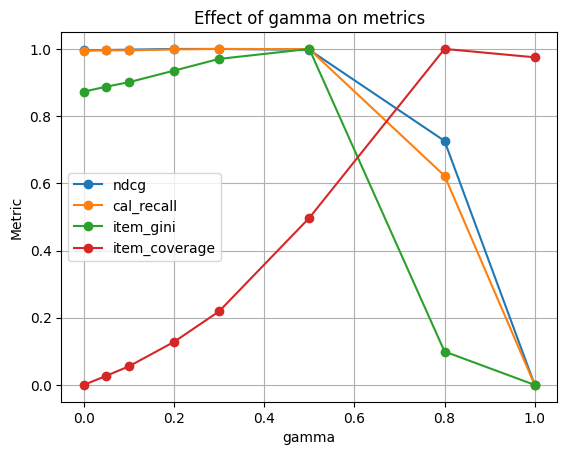

In [30]:
n_items = len(item_ids_cb) #items in CB

def eval_preds(df_preds, k=TOPN):
    """
    Evaluate a recommendation DataFrame (user_id, item_id, rank) using our metrics.
    """
    df2 = get_top_k(df_preds[["user_id", "item_id"]], k) #keep top k recommendations per users
    return {
        "ndcg": calculate_ndcg(df2, k=k, test_out=test_out_df),
        "cal_recall": calculate_calibrated_recall(df2, k=k, test_out=test_out_df),
        "item_gini": calculate_item_gini(df2, k=k),
        "item_coverage": calculate_item_coverage(df2, k=k, n_items=n_items),
    }

#gamma values
gammas = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0]

rows = []
for gamma in gammas:
    #apply post-hoc popularity penalty
    scores_pop = popularity_penalty_rerank(scores_hybrid, item_ids_cb, train_data, gamma=gamma)

    #convert to recommendations
    preds_pop = recommend_topn_from_scores(
        scores_pop,
        user_ids=user_ids.to_numpy(),
        item_ids_cb=item_ids_cb,
        topn=TOPN
    )

    #evaluate results
    metrics = eval_preds(preds_pop, k=TOPN)
    metrics["gamma"] = gamma
    rows.append(metrics)

#collect all results
results_pop = pd.DataFrame(rows).sort_values("gamma").reset_index(drop=True)
results_pop

df = results_pop.sort_values("gamma").reset_index(drop=True)
metrics = ["ndcg", "cal_recall", "item_gini", "item_coverage"]

# Min–max normalization
df_norm = df.copy()
for m in metrics:
    x = df_norm[m].to_numpy(dtype=float)
    mn, mx = np.min(x), np.max(x)
    df_norm[m] = 0.0 if mx == mn else (x - mn) / (mx - mn)

plt.figure()
for m in metrics:
    plt.plot(df_norm["gamma"], df_norm[m], marker="o", label=m)

plt.xlabel("gamma")
plt.ylabel("Metric")
plt.title("Effect of gamma on metrics")
plt.grid(True)
plt.legend()
plt.show()


- We save the results

In [ ]:
scores_pop = popularity_penalty_rerank(scores_hybrid, item_ids_cb, train_data, gamma=0.4)
preds_pop2 = recommend_topn_from_scores(scores_pop, user_ids=user_ids.to_numpy(), item_ids_cb=item_ids_cb, topn=TOPN)
submission_pop = preds_pop2[["user_id", "item_id"]].copy()
submission_pop.to_csv("submission_pop.csv", index=False)

### **2. Maximal Marginal Relevance**

In [33]:
def mmr_rerank(scores: sp.csr_matrix,
               user_ids: np.ndarray,
               item_ids_cb: np.ndarray,
               sim_mat: np.ndarray,
               topn: int = 20,
               candidate_M: int = 200,
               lambda_mmr: float = 0.7) -> pd.DataFrame:
    """
    scores: CSR 
    sim_mat: item-item similarity matrix
    """
    scores = scores.tocsr()
    rows = []

    for u_idx in range(scores.shape[0]):
        row = scores.getrow(u_idx)
        if row.nnz == 0:
            continue

        #candidates: top m items
        idx = row.indices
        val = row.data
        M = min(candidate_M, val.size)
        if val.size > M:
            pos = np.argpartition(-val, M-1)[:M]
            cand_idx = idx[pos]
            cand_val = val[pos]
        else:
            cand_idx = idx
            cand_val = val

        #sort candidates by descending relevance 
        order = np.argsort(-cand_val)
        cand_idx = cand_idx[order]
        cand_val = cand_val[order]

        #keep track of the selected items
        selected = []
        selected_set = set()

        rel = {int(j): float(s) for j, s in zip(cand_idx, cand_val)}

        #MMR selection 
        while len(selected) < min(topn, len(cand_idx)):
            best_j = None
            best_score = -np.inf

            for j in cand_idx:
                j = int(j)
                if j in selected_set:
                    continue
                
                #diversity penalty, similarity to the already selected item
                if not selected:
                    div_pen = 0.0
                else:
                    div_pen = max(sim_mat[j, s] for s in selected)

                mmr_score = lambda_mmr * rel[j] - (1.0 - lambda_mmr) * div_pen

                if mmr_score > best_score:
                    best_score = mmr_score
                    best_j = j

            if best_j is None:
                break

            selected.append(best_j)
            selected_set.add(best_j)

        #convert selected internal indices back to real id
        u_real = int(user_ids[u_idx])
        for rank, j in enumerate(selected, start=1):
            rows.append({"user_id": u_real, "item_id": int(item_ids_cb[j]), "rank": rank})

    return pd.DataFrame(rows, columns=["user_id", "item_id", "rank"])


In [36]:
sim_mat = np.asarray(similarity_matrix)
#lambda values
lambdas = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0]

rows = []
for lam in lambdas:
    #apply pots-hoc
    preds_mmr = mmr_rerank(
        scores_hybrid,
        user_ids=user_ids.to_numpy(),
        item_ids_cb=item_ids_cb,
        sim_mat=sim_mat,
        topn=TOPN,
        candidate_M=200,
        lambda_mmr=lam
    )

    #evaluate results
    metrics = eval_preds(preds_mmr, k=TOPN)
    metrics["lambda_mmr"] = lam
    rows.append(metrics)

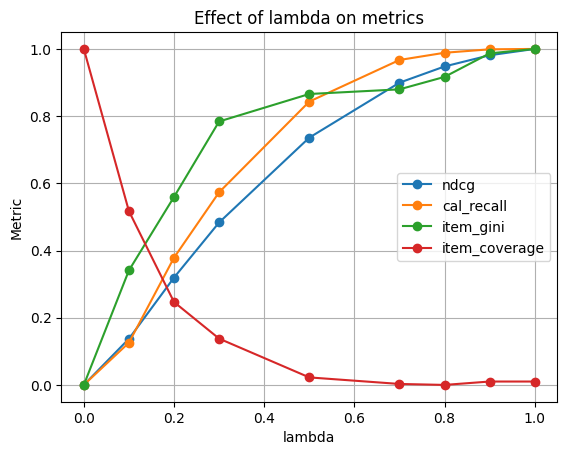

In [37]:
#store results in a table
results_mmr = pd.DataFrame(rows).sort_values("lambda_mmr").reset_index(drop=True)
df = results_mmr.sort_values("lambda_mmr").reset_index(drop=True)

metrics = ["ndcg", "cal_recall", "item_gini", "item_coverage"]

df_norm = df.copy()
for m in metrics:
    x = df_norm[m].to_numpy(dtype=float)
    mn, mx = np.min(x), np.max(x)
    df_norm[m] = 0.0 if mx == mn else (x - mn) / (mx - mn)

plt.figure()
for m in metrics:
    plt.plot(df_norm["lambda_mmr"], df_norm[m], marker="o", label=m)

plt.xlabel("lambda")
plt.ylabel("Metric")
plt.title("Effect of lambda on metrics")
plt.grid(True)
plt.legend()
plt.show()

- Save results

In [39]:
preds_mmr2 = mmr_rerank(scores_hybrid,
                       user_ids=user_ids.to_numpy(),
                       item_ids_cb=item_ids_cb,
                       sim_mat=similarity_matrix,
                       topn=TOPN,
                       candidate_M=200,
                       lambda_mmr=0.3)

submission_mmr = preds_mmr2[["user_id", "item_id"]].copy()
submission_mmr.to_csv("submission_mmr.csv", index=False)